# Session 1 — can ETS, ARIMA, or seasonal ARIMA beat the baseline?

This notebook reads the completed experiment in `results/`. To refit everything, run `python session1_models.py` from the activated environment. All models use only the supplied generation history; weather is deliberately excluded from this comparison.

## What is the baseline?
**Daily seasonal naive** repeats the last 24 hourly generation values twice to predict 48 hours. If the last observed day had generation 100 at 10:00, it predicts 100 at 10:00 on both future days. There are no fitted coefficients.

The assignment estimates the standard deviation of historical 24-hour differences and uses intervals `forecast ± 1.96 × sigma × sqrt(day_number)`, clipping the lower bound to zero. Day two therefore has a wider interval.

## How do I know whether I beat it?
Compare predictions with actual values on the **same held-back hours**:

- **RMSE**: square errors, average them, take the square root. Lower is better; large misses matter strongly.
- **RMSE ratio = model RMSE / baseline RMSE**. Below 1 beats baseline; e.g. 0.8 means 20% lower RMSE. Session 1's benchmark-beating points use this ratio on the hidden 48 hours.
- **MAPE**: average absolute percentage error. Lower is better, but tiny actual generation can make it very large.
- **Winkler**: interval width plus a penalty for misses. Lower is better.
- **Coverage**: fraction inside the nominal 95% interval. Near 95% is the target over many forecasts; 100% does not automatically mean a good interval because it may be too wide.

Validation provides evidence, not a guarantee. Only the instructor can score the hidden future values.

## Experimental design
We use twelve consecutive nonoverlapping 48-hour blocks at the end of history: six for interval calibration, five for choosing the model, and the last for an audit. **The audit was already seen during EDA and an initial trial; it is not an untouched test set.** It does not select the winner.

Each model refits using only information before its forecast origin. Training windows of 7, 21, or 60 days adapt to the changing scale seen in EDA. The baseline always uses all available past data for its interval, exactly as in the assignment. Candidate selection uses pooled RMSE across the five selection blocks, with baseline eligible as a fallback.

Candidate intervals use the 95th percentile of absolute forecast errors from the six earlier calibration blocks, separately for day one and day two. Their coverage is checked on later blocks. Serial dependence and changing variance mean this does not guarantee 95% future coverage. For the actual future forecast, interval calibration is refreshed with all completed historical blocks.

## What the models do
| Model | Interpretation |
|---|---|
| ETS(A,N,A) | Exponential smoothing of a changing level and additive daily seasonal pattern; no trend. |
| ETS(A,Ad,A) | Adds a damped trend, whose projected effect gradually flattens. |
| ARIMA(2,1,2) | Models changes using two autoregressive and two moving-average terms; no explicit daily seasonality. |
| SARIMA(1,0,1)(1,1,0)[24] | Takes daily seasonal differences, with short-term AR/MA dependence and one seasonal AR term. |

ETS means error, trend, seasonal components. These are a small prespecified candidate set, not an exhaustive order search. ARIMA and SARIMA are fitted through statsmodels' [state-space interface](https://www.statsmodels.org/stable/statespace.html). Optimization warnings are saved in `results/run_summary.json`; failed fits are not silently accepted.


In [ ]:
# Run from the repository root so data and results paths resolve.
import os, sys
from pathlib import Path
if Path.cwd().name == 'notebooks':
    os.chdir('..')
sys.path.insert(0, str(Path.cwd()))
sys.path.insert(0, str(Path.cwd()/'scripts'))

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf
results_dir = Path("results/ets_arima")
comparison = pd.read_csv(results_dir / "model_comparison.csv", index_col="model")
scores = pd.read_csv(results_dir / "validation_scores.csv")
pred = pd.read_csv(results_dir / "validation_predictions.csv", parse_dates=["ds"])
report = json.loads((results_dir / "run_summary.json").read_text())
winner = report["selected_model"]
print("Selected model:", winner)
display(comparison.round(3))
ratio = comparison.loc[winner, "RMSE_ratio"]
print(f"Selection RMSE reduction: {100*(1-ratio):.1f}% across five windows")


Selected model: SARIMA_101_110_24_21d


,RMSE,MAPE,Winkler,coverage,mean_width,RMSE_ratio,windows_beating_baseline
model,,,,,,,
SARIMA_101_110_24_21d,295.532,490.494,1173.162,0.975,1137.493,0.944,4
SARIMA_101_110_24_60d,299.936,490.361,1175.784,0.979,1147.832,0.958,4
seasonal_naive,312.953,765.279,2206.476,0.796,615.930,1.000,0
SARIMA_101_110_24_7d,316.427,383.296,1340.195,0.950,1161.476,1.011,3
ETS_ANA_21d,381.366,403.763,1849.131,0.858,998.702,1.219,1
ETS_ANA_7d,397.255,439.391,1763.263,0.862,1076.655,1.269,1
ETS_AAdA_21d,397.274,511.728,2130.329,0.846,988.348,1.269,1
ARIMA_212_21d,717.514,2488.078,2688.779,0.950,2181.905,2.293,0


Selection RMSE reduction: 5.6% across five windows


## Consistency across windows
A low average can hide failures. Inspect both the pooled scores and the number of windows won.

model,ARIMA_212_21d,ETS_AAdA_21d,ETS_ANA_21d,ETS_ANA_7d,SARIMA_101_110_24_21d,SARIMA_101_110_24_60d,SARIMA_101_110_24_7d,seasonal_naive
start,,,,,,,,
2026-10-15 01:00:00,2.072,1.359,1.311,1.111,0.937,0.943,0.913,1.0
2026-10-17 01:00:00,2.053,1.086,1.122,1.175,0.849,0.892,1.161,1.0
2026-10-19 01:00:00,2.545,0.393,0.387,0.552,0.983,0.957,0.666,1.0
2026-10-21 01:00:00,2.900,1.356,1.271,1.816,1.236,1.246,1.221,1.0
2026-10-23 01:00:00,2.944,2.497,2.186,2.397,0.972,0.979,0.942,1.0


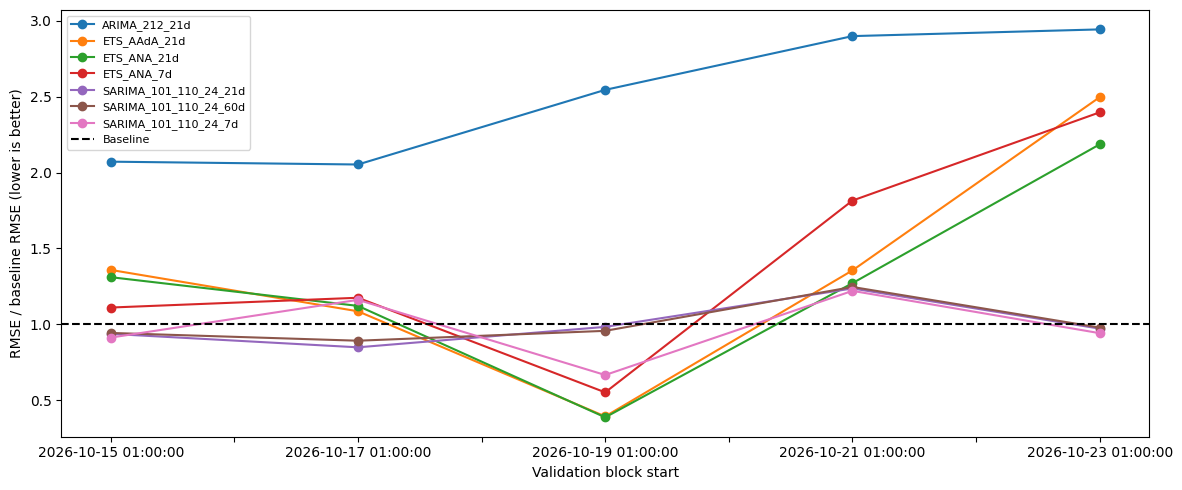

In [2]:
selection = scores[scores.phase == "selection"]
pivot = selection.pivot(index="start", columns="model", values="RMSE")
ratios = pivot.div(pivot["seasonal_naive"], axis=0)
display(ratios.round(3))
ax = ratios.drop(columns="seasonal_naive").plot(marker="o", figsize=(12,5))
ax.axhline(1, color="black", linestyle="--", label="Baseline")
ax.set_ylabel("RMSE / baseline RMSE (lower is better)")
ax.set_xlabel("Validation block start"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


## Last-window audit
This is the same 48-hour window used in EDA, reported separately from the selection windows.

,RMSE,MAPE,Winkler,coverage,mean_width
model,,,,,
seasonal_naive,120.404,51.088,568.464,1.000,568.464
ETS_ANA_7d,296.483,60.056,1069.599,0.958,1009.669
ETS_ANA_21d,364.824,74.337,1773.143,0.875,956.488
ETS_AAdA_21d,374.230,83.911,1886.813,0.875,947.521
ARIMA_212_21d,344.918,271.002,1831.131,1.000,1831.131
SARIMA_101_110_24_7d,113.782,37.354,1034.229,1.000,1034.229
SARIMA_101_110_24_21d,116.108,38.789,1017.788,1.000,1017.788
SARIMA_101_110_24_60d,117.239,39.070,1024.960,1.000,1024.960


Selected model / baseline RMSE on last window: 0.964


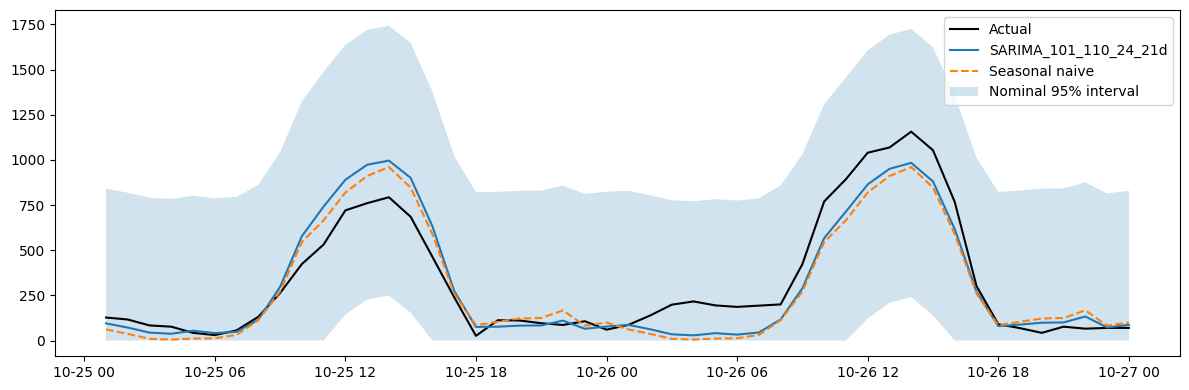

In [3]:
audit = scores[scores.phase == "last_window_audit"].set_index("model")
display(audit[["RMSE", "MAPE", "Winkler", "coverage", "mean_width"]].round(3))
audit_ratio = audit.loc[winner, "RMSE"] / audit.loc["seasonal_naive", "RMSE"]
print(f"Selected model / baseline RMSE on last window: {audit_ratio:.3f}")
g = pred[(pred.phase == "last_window_audit") & (pred.model == winner)]
b = pred[(pred.phase == "last_window_audit") & (pred.model == "seasonal_naive")]
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(g.ds, g.actual, color="black", label="Actual")
ax.plot(g.ds, g.forecast, label=winner)
ax.plot(b.ds, b.forecast, linestyle="--", label="Seasonal naive")
ax.fill_between(g.ds, g.lower_95, g.upper_95, alpha=.2, label="Nominal 95% interval")
ax.legend(); plt.tight_layout(); plt.show()


## Forecast-error diagnostics
These are held-back multi-step forecast errors, not one-step training residuals. Persistent patterns suggest information the model misses. The ACF spans consecutive selection blocks with refits every 48 hours and is descriptive.

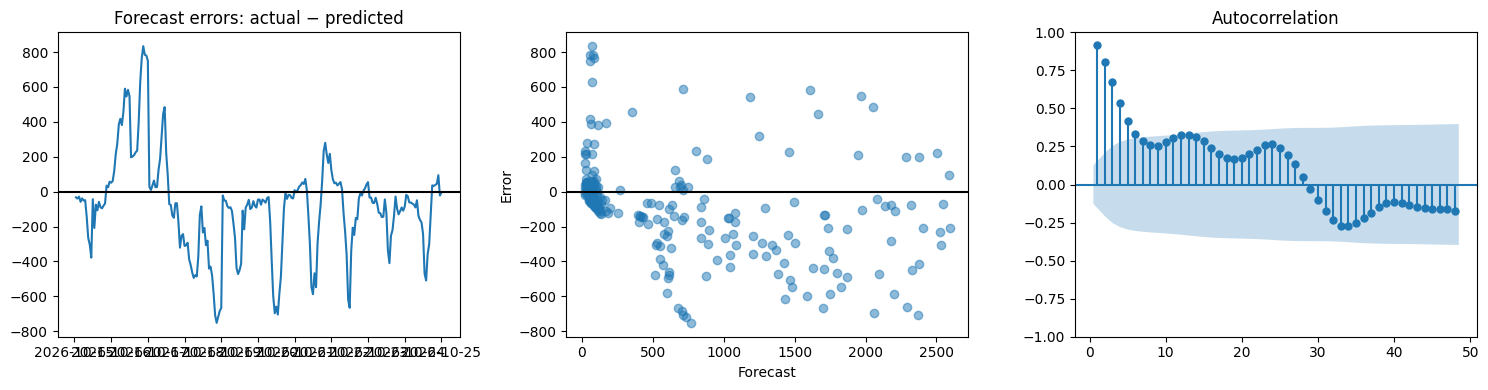

,RMSE,bias_actual_minus_forecast,coverage
day,,,
1,200.415223,-84.820903,1.00
2,366.759507,-87.399487,0.95


In [4]:
g = pred[(pred.phase == "selection") & (pred.model == winner)].copy()
g["error"] = g.actual - g.forecast
g["day"] = np.where(g.horizon <= 24, 1, 2)
fig, axes = plt.subplots(1, 3, figsize=(15,4))
axes[0].plot(g.ds, g.error); axes[0].axhline(0, color="black"); axes[0].set_title("Forecast errors: actual − predicted")
axes[1].scatter(g.forecast, g.error, alpha=.5); axes[1].axhline(0, color="black"); axes[1].set_xlabel("Forecast"); axes[1].set_ylabel("Error")
plot_acf(g.error, lags=48, fft=True, zero=False, ax=axes[2])
plt.tight_layout(); plt.show()
display(g.groupby("day").apply(lambda x: pd.Series({"RMSE": np.sqrt(np.mean(x.error**2)), "bias_actual_minus_forecast": x.error.mean(), "coverage": ((x.actual>=x.lower_95)&(x.actual<=x.upper_95)).mean()})))


## Actual next 48 hours
The selected configuration is refitted at the end of history using its chosen recent training window. The target values for these future hours are unknown, so we cannot calculate their RMSE locally.

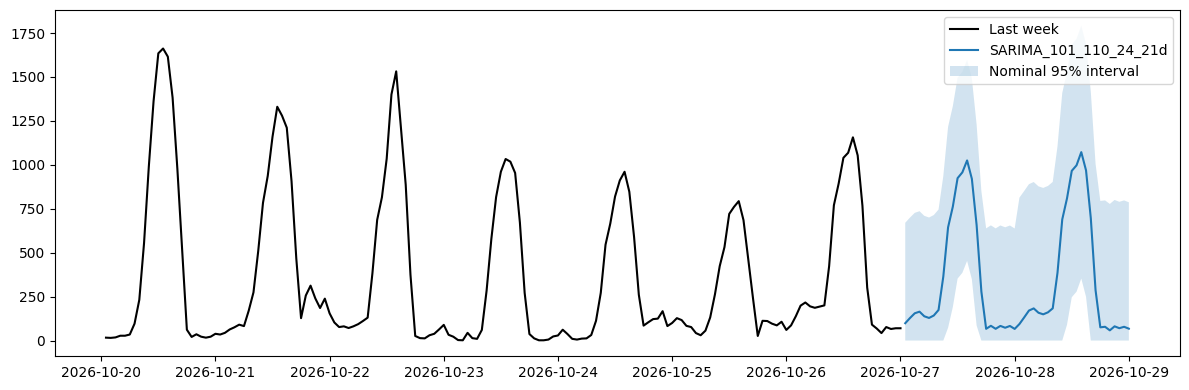

,ds,forecast,lower_95,upper_95
0,2026-10-27 01:00:00,98.600940,0.0,670.193668
1,2026-10-27 02:00:00,128.210273,0.0,699.803001
2,2026-10-27 03:00:00,155.133798,0.0,726.726526
3,2026-10-27 04:00:00,164.292893,0.0,735.885621
4,2026-10-27 05:00:00,138.071301,0.0,709.664028


In [5]:
data = pd.read_csv("train.csv", parse_dates=["ds"])
submission = pd.read_csv(results_dir / "selected_model_forecast.csv", parse_dates=["ds"])
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(data.ds.iloc[-168:], data.y.iloc[-168:], color="black", label="Last week")
ax.plot(submission.ds, submission.forecast, label=winner)
ax.fill_between(submission.ds, submission.lower_95, submission.upper_95, alpha=.2, label="Nominal 95% interval")
ax.legend(); plt.tight_layout(); plt.show()
display(submission.head())


## Save the Moodle filename
The forecast is already saved in `results/selected_model_forecast.csv`. Enter your surname below to save an identical file under the required name. This cell does not upload anything.


In [6]:
SURNAME = ""  # Fill in your surname, then run this cell.
if SURNAME.strip():
    assert not any(c in SURNAME for c in "/\\"), "Enter a surname, not a path"
    filename = f"{SURNAME.strip().upper()}_project.csv"
    output = pd.read_csv(results_dir / "selected_model_forecast.csv")
    output.to_csv(filename, index=False)
    print("Saved", filename)
else:
    print("Enter SURNAME to save the Moodle submission filename.")


Enter SURNAME to save the Moodle submission filename.
